# Case Study 2 -- Supermarket Sales: 


In [1]:
PROJECT_NAME = "Supermarket"
DATA_PATH   = "../data/supermarket_sales_case_study.csv"
OUT_DIR     = "../data"
OUT_PREFIX  = "supermarket"

ID_COL, CITY_COL, CUSTTYPE_COL = "Invoice ID", "City", "Customer type"
GENDER_COL, PAYMENT_COL = "Gender", "Payment"
QTY_COL, PRICE_COL, TOTAL_COL = "Quantity", "Unit price", "Total"
DATE_COL, TIME_COL, RATING_COL = "Date", "Time", "Rating"

TAX_RATE   = 0.05      # 5% tax
TOLERANCE  = 0.50      # Total is wrong if off by more than this
TARGET     = 100_000   # per branch per quarter

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(DATA_PATH)
rows_in = len(df)
print(df.shape)
df.head()

(8631, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,852-73-6802,A,Yangon,Normal,Female,Health and beauty,52.24,4,10.4480,219.4080,1/1/2023,12:46,Ewallet,208.96,4.761905,10.4480,7.1
1,845-69-3430,A,Yangon,Member,Male,Sports and travel,50.54,6,15.1620,318.4020,1/1/2023,17:55,Ewallet,303.24,4.761905,15.1620,8.4
2,307-57-9082,B,Mandalay,Member,Male,Fashion accessories,69.86,4,13.9720,293.4120,1/1/2023,12:40,Credit card,279.44,4.761905,13.9720,8.3
3,453-35-6332,B,Mandalay,Member,Female,Home and lifestyle,52.63,5,13.1575,276.3075,1/1/2023,17:20,Ewallet,263.15,4.761905,13.1575,7.1
4,365-74-6230,B,Mandalay,Normal,Male,Sports and travel,42.97,4,8.5940,180.4740,1/1/2023,17:36,Cash,171.88,4.761905,8.5940,5.3


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8631 entries, 0 to 8630
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               8631 non-null   str    
 1   Branch                   8631 non-null   str    
 2   City                     8631 non-null   str    
 3   Customer type            8567 non-null   str    
 4   Gender                   8631 non-null   str    
 5   Product line             8631 non-null   str    
 6   Unit price               8631 non-null   float64
 7   Quantity                 8631 non-null   int64  
 8   Tax 5%                   8631 non-null   float64
 9   Total                    8631 non-null   float64
 10  Date                     8614 non-null   str    
 11  Time                     8631 non-null   str    
 12  Payment                  8631 non-null   str    
 13  cogs                     8631 non-null   float64
 14  gross margin percentage  8631 non-n

In [4]:
audit = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2),
})
print(audit[audit.missing_count > 0])
print("exact duplicate rows:", df.duplicated().sum())
print("extra rows sharing an Invoice ID:", df[ID_COL].duplicated().sum())
print("rows involved in shared Invoice IDs:", df[ID_COL].duplicated(keep=False).sum())

               missing_count  missing_percent
Customer type             64             0.74
Date                      17             0.20
Rating                    88             1.02
exact duplicate rows: 30
extra rows sharing an Invoice ID: 55
rows involved in shared Invoice IDs: 110


In [5]:
print(df[GENDER_COL].unique())
print(df[PAYMENT_COL].unique())

<StringArray>
['Female', 'Male', ' Female', 'MALE ', 'male', 'female']
Length: 6, dtype: str
<StringArray>
['Ewallet', 'Credit card', 'Cash', 'cash', ' Credit card', 'ewallet ',
 'EWALLET']
Length: 7, dtype: str


In [6]:
trail = [{"step": "raw file loaded", "rows": len(df)}]   # audit trail ledger (Step 10)

# Step 3: exact duplicates (resent upload) -> remove copies
print("Before exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("After cleaning exact duplicate rows:", df.duplicated().sum())
trail.append({"step": "exact duplicates dropped", "rows": len(df)})

Before exact duplicate rows: 30
After cleaning exact duplicate rows: 0


In [7]:
# Step 4: conflicting Invoice IDs
# RULE: the later row is a correction, so keep the LAST row for each Invoice ID.
before = len(df)
df = df.drop_duplicates(subset=ID_COL, keep="last")
conflicts_resolved = before - len(df)
print("conflicting records resolved:", conflicts_resolved)
trail.append({"step": "conflicting Invoice IDs resolved (keep last)", "rows": len(df)})

conflicting records resolved: 25


In [8]:
# Step 5: standardise text columns (strip + lower, then map to one correct spelling)
gender_map  = {"male": "Male", "female": "Female"}
payment_map = {"cash": "Cash", "credit card": "Credit card", "ewallet": "Ewallet"}

df[GENDER_COL]  = df[GENDER_COL].str.strip().str.lower().map(gender_map)
df[PAYMENT_COL] = df[PAYMENT_COL].str.strip().str.lower().map(payment_map)
print("unmapped gender:", df[GENDER_COL].isna().sum(), "| unmapped payment:", df[PAYMENT_COL].isna().sum())
print(df[GENDER_COL].unique(), df[PAYMENT_COL].unique())
trail.append({"step": "text columns standardised", "rows": len(df)})

unmapped gender: 0 | unmapped payment: 0
<StringArray>
['Female', 'Male']
Length: 2, dtype: str <StringArray>
['Ewallet', 'Credit card', 'Cash']
Length: 3, dtype: str


In [9]:
# Step 6: negative quantities (minus sign = typing error)
neg_fixed = (df[QTY_COL] < 0).sum()
df[QTY_COL] = df[QTY_COL].abs()
print("negative quantities fixed:", neg_fixed)
trail.append({"step": "negative quantities fixed", "rows": len(df)})

negative quantities fixed: 57


In [10]:
# Step 7: mixed dates -> try month/day/year first, then day-month-year, anything else = missing
date_1 = pd.to_datetime(df[DATE_COL], format="%m/%d/%Y", errors="coerce")
date_2 = pd.to_datetime(df[DATE_COL], format="%d-%m-%Y", errors="coerce")
parsed = date_1.fillna(date_2)

print("unparseable text values:", df.loc[parsed.isna() & df[DATE_COL].notna(), DATE_COL].unique())
df[DATE_COL] = parsed
print("missing dates after parsing:", df[DATE_COL].isna().sum())
trail.append({"step": "dates parsed (bad ones -> missing)", "rows": len(df)})

unparseable text values: <StringArray>
['not a date', '32/01/2024']
Length: 2, dtype: str
missing dates after parsing: 62


In [11]:
# Step 8: check Total = Quantity x Unit price x 1.05 ; replace if off by more than 0.50
expected_total = df[QTY_COL] * df[PRICE_COL] * (1 + TAX_RATE)
total_bad = (df[TOTAL_COL] - expected_total).abs() > TOLERANCE
total_fixed = total_bad.sum()
df.loc[total_bad, TOTAL_COL] = expected_total[total_bad].round(2)
print("Total errors fixed:", total_fixed)
trail.append({"step": "Total checked / fixed", "rows": len(df)})

Total errors fixed: 62


In [12]:
# Step 9: handle what is still missing
df[CUSTTYPE_COL] = df[CUSTTYPE_COL].fillna("Unknown")
df[RATING_COL]   = df[RATING_COL].fillna(df[RATING_COL].median())

df_clean = df[df[DATE_COL].notna()].copy()    # no date = cannot be placed in a quarter
print("rows kept:", len(df_clean))
print(df_clean.isnull().sum().sum(), "missing values left")
trail.append({"step": "no-date rows dropped (missing filled)", "rows": len(df_clean)})

rows kept: 8514
0 missing values left


In [13]:
df_clean.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,852-73-6802,A,Yangon,Normal,Female,Health and beauty,52.24,4,10.4480,219.4080,2023-01-01,12:46,Ewallet,208.96,4.761905,10.4480,7.1
1,845-69-3430,A,Yangon,Member,Male,Sports and travel,50.54,6,15.1620,318.4020,2023-01-01,17:55,Ewallet,303.24,4.761905,15.1620,8.4
2,307-57-9082,B,Mandalay,Member,Male,Fashion accessories,69.86,4,13.9720,293.4120,2023-01-01,12:40,Credit card,279.44,4.761905,13.9720,8.3
3,453-35-6332,B,Mandalay,Member,Female,Home and lifestyle,52.63,5,13.1575,276.3075,2023-01-01,17:20,Ewallet,263.15,4.761905,13.1575,7.1
4,365-74-6230,B,Mandalay,Normal,Male,Sports and travel,42.97,4,8.5940,180.4740,2023-01-01,17:36,Cash,171.88,4.761905,8.5940,5.3


In [14]:
audit_trail = pd.DataFrame(trail)
audit_trail["removed"] = (audit_trail["rows"].shift(1) - audit_trail["rows"]).fillna(0).astype(int)
audit_trail

,step,rows,removed
0,raw file loaded,8631,0
1,exact duplicates dropped,8601,30
2,conflicting Invoice IDs resolved (keep last),8576,25
3,text columns standardised,8576,0
4,negative quantities fixed,8576,0
5,dates parsed (bad ones -> missing),8576,0
6,Total checked / fixed,8576,0
7,no-date rows dropped (missing filled),8514,62


In [15]:
df_clean["Year"] = df_clean[DATE_COL].dt.year
df_clean["Quarter"] = df_clean[DATE_COL].dt.to_period("Q").astype(str)   # e.g. 2023Q1
df_clean["Day_of_week"] = df_clean[DATE_COL].dt.day_name()
df_clean["Hour"] = pd.to_datetime(df_clean[TIME_COL], format="%H:%M").dt.hour
df_clean[[DATE_COL, TIME_COL, "Year", "Quarter", "Day_of_week", "Hour"]].head()

,Date,Time,Year,Quarter,Day_of_week,Hour
0,2023-01-01,12:46,2023,2023Q1,Sunday,12
1,2023-01-01,17:55,2023,2023Q1,Sunday,17
2,2023-01-01,12:40,2023,2023Q1,Sunday,12
3,2023-01-01,17:20,2023,2023Q1,Sunday,17
4,2023-01-01,17:36,2023,2023Q1,Sunday,17


In [16]:
# Stores open 10:00-21:00 -> Morning 10-13 (3h), Afternoon 13-17 (4h), Evening 17-21 (4h)
conditions = [
    df_clean["Hour"].between(10, 12),
    df_clean["Hour"].between(13, 16),
    df_clean["Hour"].between(17, 20),
]
choices = ["Morning", "Afternoon", "Evening"]
df_clean["Time_of_day"] = np.select(conditions, choices, default="Other")

hours_in_bucket = pd.Series({"Morning": 3, "Afternoon": 4, "Evening": 4})
counts = df_clean["Time_of_day"].value_counts()
print(counts)
tx_per_hour = (counts / hours_in_bucket).dropna().round(1).sort_values(ascending=False)
print("\ntransactions per hour:")
print(tx_per_hour)

Time_of_day
Evening      3409
Afternoon    2953
Morning      2152
Name: count, dtype: int64

transactions per hour:
Time_of_day
Evening      852.2
Afternoon    738.2
Morning      717.3
dtype: float64


In [17]:
revenue_q = (
    df_clean.groupby([CITY_COL, "Quarter"])[TOTAL_COL].sum().round(2).reset_index(name="Revenue")
)
targets = pd.DataFrame({CITY_COL: sorted(df_clean[CITY_COL].unique()), "Target": TARGET})

q = revenue_q.merge(targets, on=CITY_COL, how="left")
q["Variance"] = (q["Revenue"] - q["Target"]).round(2)
q["Pct_of_target"] = (q["Revenue"] / q["Target"] * 100).round(1)
q["Hit"] = q["Revenue"] >= q["Target"]
print("unmatched targets:", q["Target"].isna().sum())
q

unmatched targets: 0


,City,Quarter,Revenue,Target,Variance,Pct_of_target,Hit
0,Mandalay,2023Q1,96366.00,100000,-3634.00,96.4,False
1,Mandalay,2023Q2,91993.33,100000,-8006.67,92.0,False
2,Mandalay,2023Q3,84757.89,100000,-15242.11,84.8,False
3,Mandalay,2023Q4,109628.70,100000,9628.70,109.6,True
4,Mandalay,2024Q1,83503.15,100000,-16496.85,83.5,False
5,Mandalay,2024Q2,79174.14,100000,-20825.86,79.2,False
6,Mandalay,2024Q3,83812.84,100000,-16187.16,83.8,False
7,Mandalay,2024Q4,116106.48,100000,16106.48,116.1,True
8,Naypyitaw,2023Q1,100406.10,100000,406.10,100.4,True
9,Naypyitaw,2023Q2,82013.98,100000,-17986.02,82.0,False


In [18]:
yearly = df_clean.pivot_table(values=TOTAL_COL, index=CITY_COL, columns="Year", aggfunc="sum")

branch_summary = q.groupby(CITY_COL).agg(
    avg_quarterly_revenue=("Revenue", "mean"),
    quarters_hit=("Hit", "sum"),
)
branch_summary["avg_pct_of_target"] = (branch_summary["avg_quarterly_revenue"] / TARGET * 100).round(1)
branch_summary["best_quarter"]  = q.loc[q.groupby(CITY_COL)["Revenue"].idxmax()].set_index(CITY_COL)["Quarter"]
branch_summary["worst_quarter"] = q.loc[q.groupby(CITY_COL)["Revenue"].idxmin()].set_index(CITY_COL)["Quarter"]
branch_summary["yoy_growth_pct"] = ((yearly[2024] / yearly[2023] - 1) * 100).round(1)
branch_summary["avg_quarterly_revenue"] = branch_summary["avg_quarterly_revenue"].round(2)
branch_summary

,avg_quarterly_revenue,quarters_hit,avg_pct_of_target,best_quarter,worst_quarter,yoy_growth_pct
City,,,,,,
Mandalay,93167.82,2,93.2,2024Q4,2024Q2,-5.3
Naypyitaw,103296.89,4,103.3,2024Q4,2023Q2,8.4
Yangon,103798.63,4,103.8,2023Q4,2024Q3,1.1


## 8. Find the Busy Times

In [19]:
# average per day = transactions on that weekday / number of those weekdays in the data
all_days = pd.Series(pd.date_range(df_clean[DATE_COL].min(), df_clean[DATE_COL].max()))
n_weekdays = all_days.dt.day_name().value_counts()

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
per_day = (df_clean["Day_of_week"].value_counts() / n_weekdays).reindex(order).round(2)
per_day

Day_of_week
Monday        9.19
Tuesday       9.71
Wednesday    10.20
Thursday     10.29
Friday       12.59
Saturday     15.42
Sunday       14.14
Name: count, dtype: float64

In [20]:
hour_counts = pd.crosstab(df_clean["Day_of_week"], df_clean["Hour"]).reindex(order)
heat = hour_counts.div(n_weekdays.reindex(order), axis=0)
heat.round(2)

Hour,10,11,12,13,14,15,16,17,18,19,20
Day_of_week,,,,,,,,,,,
Monday,0.34,0.61,1.19,1.00,0.56,0.51,0.91,1.12,1.30,1.05,0.58
Tuesday,0.39,0.66,1.24,0.92,0.57,0.55,0.77,1.25,1.65,1.17,0.54
Wednesday,0.44,0.61,1.50,0.90,0.64,0.58,0.67,1.48,1.64,1.27,0.46
Thursday,0.40,0.81,1.31,1.07,0.62,0.76,0.62,1.26,1.62,1.34,0.48
Friday,0.49,0.82,1.43,1.28,0.82,0.80,0.99,1.58,2.20,1.54,0.64
Saturday,0.83,1.61,2.03,1.80,1.61,1.46,1.55,1.54,1.53,0.90,0.58
Sunday,0.85,1.25,1.82,1.68,1.59,1.64,1.40,1.38,1.21,0.84,0.50


## 9. Chart

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

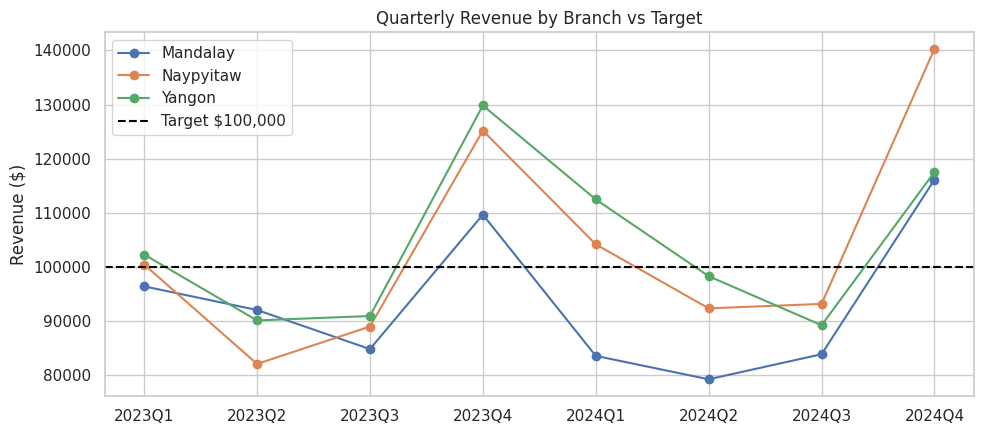

In [22]:
pivot_q = q.pivot(index="Quarter", columns=CITY_COL, values="Revenue")

fig, ax = plt.subplots(figsize=(10, 4.5))
for city in pivot_q.columns:
    ax.plot(pivot_q.index, pivot_q[city], marker="o", label=city)
ax.axhline(TARGET, color="black", linestyle="--", label=f"Target ${TARGET:,}")
ax.set_title("Quarterly Revenue by Branch vs Target")
ax.set_ylabel("Revenue ($)")
ax.legend()
plt.tight_layout()
plt.show()

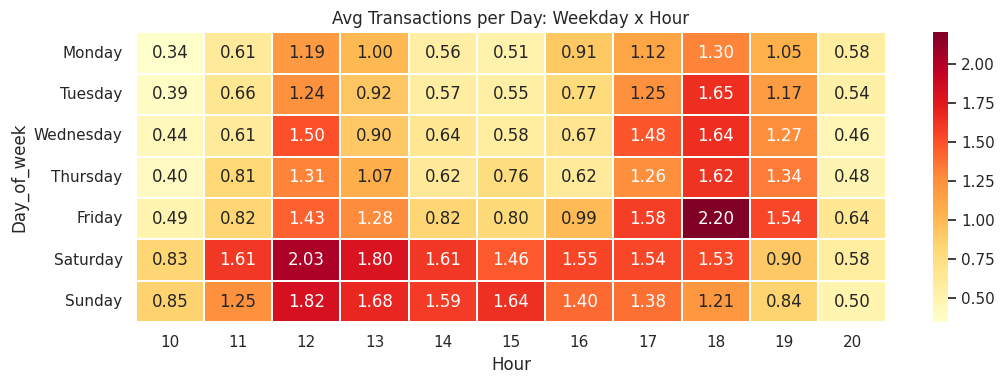

In [23]:
plt.figure(figsize=(11, 4))
sns.heatmap(heat, cmap="YlOrRd", linewidths=0.3, annot=True, fmt=".2f")
plt.title("Avg Transactions per Day: Weekday x Hour")
plt.tight_layout()
plt.show()

## 10. Exporting the Results

In [24]:
df_clean.to_csv(f"{OUT_DIR}/{OUT_PREFIX}_clean.csv", index=False)
q.to_csv(f"{OUT_DIR}/{OUT_PREFIX}_quarterly_vs_target.csv", index=False)
audit_trail.to_json(f"{OUT_DIR}/{OUT_PREFIX}_audit_trail.json", orient="records", indent=2)
print(f"wrote {len(df_clean):,} clean rows, {len(q)} branch-quarter rows, and the audit trail")

wrote 8,514 clean rows, 24 branch-quarter rows, and the audit trail


## 11. Executive Summary

In [25]:
best = branch_summary["avg_pct_of_target"].idxmax()
worst = branch_summary["avg_pct_of_target"].idxmin()
print(f"Rows loaded:              {rows_in:,}")
print(f"Rows after cleaning:       {len(df_clean):,} ({len(df_clean)/rows_in*100:.1f}% kept)")
print(f"Trustworthy total revenue: ${df_clean[TOTAL_COL].sum():,.2f} ({df_clean[DATE_COL].min().date()} to {df_clean[DATE_COL].max().date()})")
print(f"Best branch (avg quarter): {best} at {branch_summary.loc[best,'avg_pct_of_target']}% of target, hit {branch_summary.loc[best,'quarters_hit']}/8 quarters")
print(f"Weakest branch:            {worst} at {branch_summary.loc[worst,'avg_pct_of_target']}% of target, hit {branch_summary.loc[worst,'quarters_hit']}/8 quarters")
print(f"Busiest day of week:       {per_day.idxmax()}")
print(f"Busiest time of day:       {tx_per_hour.index[0]} (per trading hour)")
print(f"Total/tax errors fixed:    {total_fixed}")
print(f"Negative quantities fixed: {neg_fixed}")
print(f"Conflicting records resolved: {conflicts_resolved}")

Rows loaded:              8,631
Rows after cleaning:       8,514 (98.6% kept)
Trustworthy total revenue: $2,402,106.66 (2023-01-01 to 2024-12-31)
Best branch (avg quarter): Yangon at 103.8% of target, hit 4/8 quarters
Weakest branch:            Mandalay at 93.2% of target, hit 2/8 quarters
Busiest day of week:       Saturday
Busiest time of day:       Evening (per trading hour)
Total/tax errors fixed:    62
Negative quantities fixed: 57
Conflicting records resolved: 25


### Five-line summary for management

In [26]:
print(f"1. We cleaned {rows_in:,} raw rows down to {len(df_clean):,} trustworthy ones; total revenue is ${df_clean[TOTAL_COL].sum():,.0f}.")
print(f"2. {best} is the strongest branch ({branch_summary.loc[best,'avg_pct_of_target']}% of the $100k quarterly target); {worst} is the weakest ({branch_summary.loc[worst,'avg_pct_of_target']}%).")
print(f"3. Across all branches, {int(q['Hit'].sum())} of {len(q)} branch-quarters hit target.")
print(f"4. Busiest day is {per_day.idxmax()}; busiest part of the day is the {tx_per_hour.index[0]}.")
print(f"5. Data fixes applied: {conflicts_resolved} conflicting invoices, {neg_fixed} negative quantities, {total_fixed} wrong totals.")

1. We cleaned 8,631 raw rows down to 8,514 trustworthy ones; total revenue is $2,402,107.
2. Yangon is the strongest branch (103.8% of the $100k quarterly target); Mandalay is the weakest (93.2%).
3. Across all branches, 10 of 24 branch-quarters hit target.
4. Busiest day is Saturday; busiest part of the day is the Evening.
5. Data fixes applied: 25 conflicting invoices, 57 negative quantities, 62 wrong totals.
